# Práctica 1 - Redes Neuronales Convolucionales: Detección de Melanomas

**Problema:** Clasificación binaria de lesiones cutáneas, benigna o maligna.

## 0. Carga de librerías y datos

In [3]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image, ImageOps, ImageFilter
from collections import Counter
import warnings

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve,
)

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

Dispositivo: cpu


In [4]:
BASE_DIR = os.path.dirname(os.path.abspath("__file__"))

TRAIN_BENIGN    = os.path.join(BASE_DIR, "melanoma_train_data_benign",    "Benign")
TRAIN_MALIGNANT = os.path.join(BASE_DIR, "melanoma_train_data_malignant", "Malignant")
TEST_BENIGN     = os.path.join(BASE_DIR, "melanoma_test_data", "test", "Benign")
TEST_MALIGNANT  = os.path.join(BASE_DIR, "melanoma_test_data", "test", "Malignant")


def list_images(folder):
    exts = {".jpg", ".jpeg", ".png", ".bmp"}
    return [os.path.join(folder, f)
            for f in os.listdir(folder)
            if os.path.splitext(f)[1].lower() in exts]


train_benign_paths    = list_images(TRAIN_BENIGN)
train_malignant_paths = list_images(TRAIN_MALIGNANT)
test_benign_paths     = list_images(TEST_BENIGN)
test_malignant_paths  = list_images(TEST_MALIGNANT)

print(f"Train - Benign:    {len(train_benign_paths):>5} imagenes")
print(f"Train - Malignant: {len(train_malignant_paths):>5} imagenes")
print(f"Test  - Benign:    {len(test_benign_paths):>5} imagenes")
print(f"Test  - Malignant: {len(test_malignant_paths):>5} imagenes")
print(f"\nTotal train: {len(train_benign_paths) + len(train_malignant_paths)}")
print(f"Total test:  {len(test_benign_paths)  + len(test_malignant_paths)}")

Train - Benign:     6289 imagenes
Train - Malignant:  5590 imagenes
Test  - Benign:     1000 imagenes
Test  - Malignant:  1000 imagenes

Total train: 11879
Total test:  2000


Se importan las librerías necesarias y se definen las rutas a los datos. El dataset está organizado en carpetas separadas para cada clase y para los conjuntos de entrenamiento y test. La semilla fija 42 se aplica a Python y NumPy para garantizar la reproducibilidad de los muestreos aleatorios en toda la exploración.

## 1. Exploración de datos

### 1.1 Distribución de clases

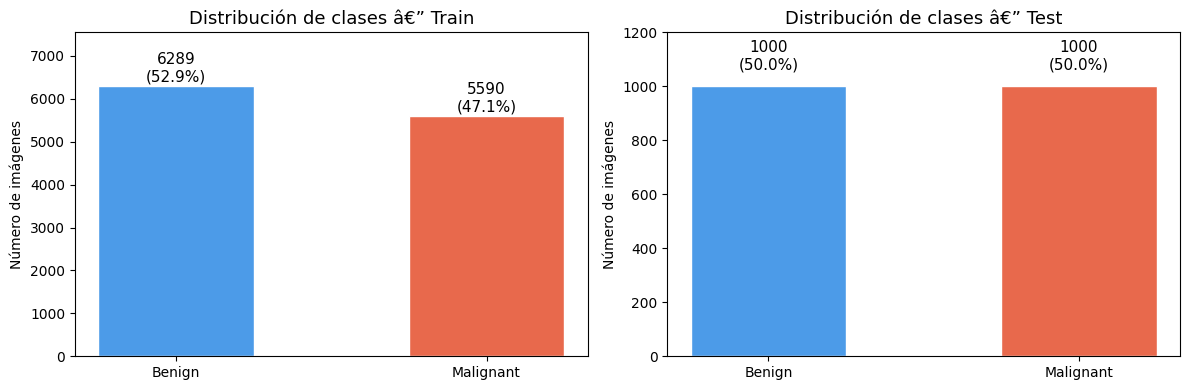

Ratio Benign/Malignant (train): 1.125
â†’ Leve desbalanceo (~53/47). No requiere técnicas agresivas, pero conviene monitorizarlo.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ["#4C9BE8", "#E8694C"]

for ax, (split_name, counts) in zip(axes, [
    ("Train", [len(train_benign_paths), len(train_malignant_paths)]),
    ("Test",  [len(test_benign_paths),  len(test_malignant_paths)]),
]):
    bars = ax.bar(["Benign", "Malignant"], counts, color=colors, edgecolor="white", width=0.5)
    ax.set_title(f"Distribución de clases â€” {split_name}", fontsize=13)
    ax.set_ylabel("Número de imágenes")
    ax.set_ylim(0, max(counts) * 1.2)
    for bar, n in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 50,
                f"{n}\n({n / sum(counts) * 100:.1f}%)",
                ha="center", va="bottom", fontsize=11)

plt.tight_layout()
plt.show()

# Ratio de desbalanceo (train)
ratio = len(train_benign_paths) / len(train_malignant_paths)
print(f"Ratio Benign/Malignant (train): {ratio:.3f}")
print("â†’ Leve desbalanceo (~53/47). No requiere técnicas agresivas, pero conviene monitorizarlo.")

El conjunto de entrenamiento contiene 6.289 imágenes benignas (52,9%) y 5.590 malignas (47,1%), lo que supone un desbalanceo leve con un ratio de 1,12. Este nivel de desbalanceo no justifica técnicas agresivas como oversampling sintético, pero obliga a monitorizar el rendimiento con F1-score y AUC en lugar de depender únicamente de la exactitud, que puede resultar engañosa en situaciones de desbalanceo. El conjunto de test está perfectamente equilibrado con 1.000 muestras por clase.

### 1.2 Inspección visual de muestras

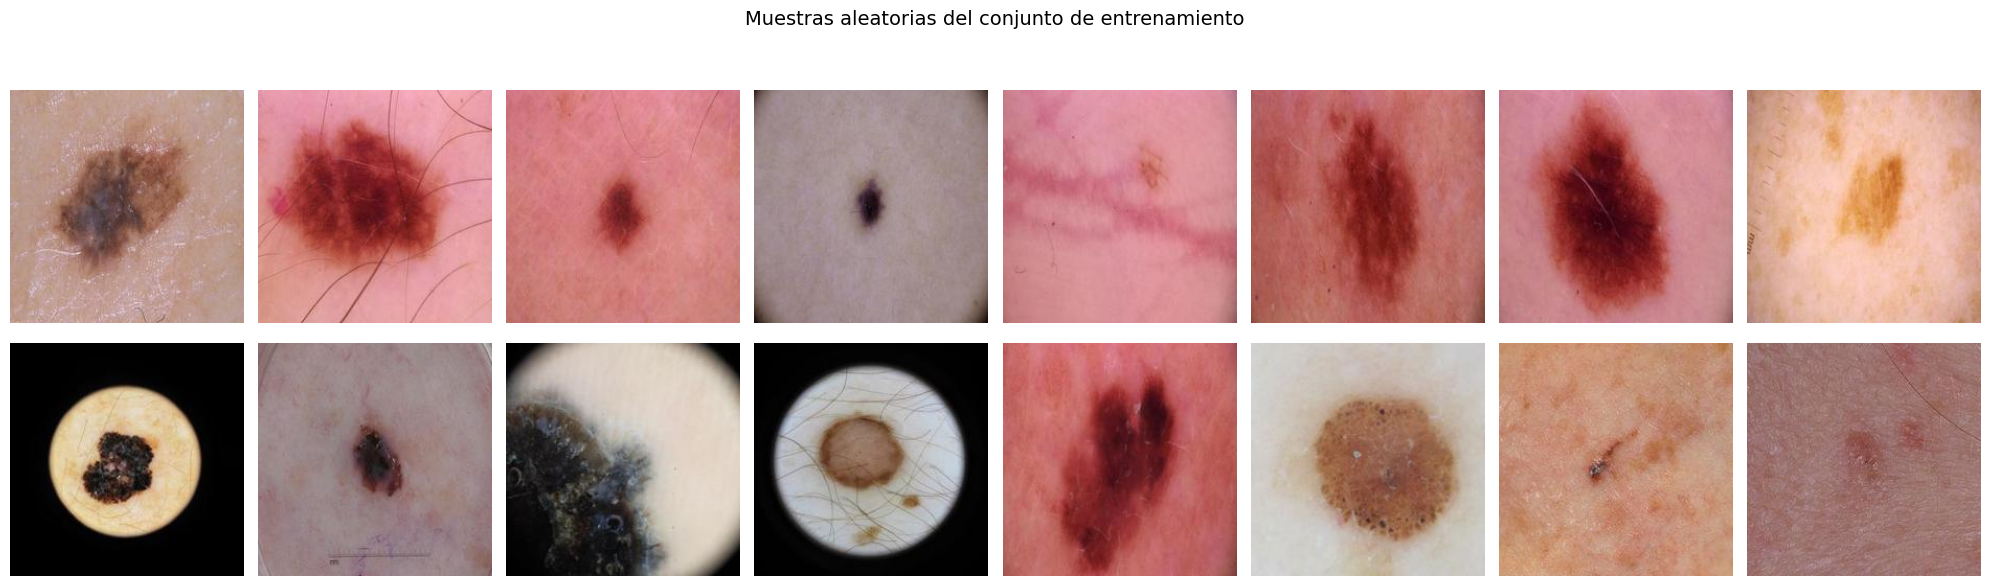

In [6]:
N_SAMPLES = 8

fig, axes = plt.subplots(2, N_SAMPLES, figsize=(20, 6))
fig.suptitle("Muestras aleatorias del conjunto de entrenamiento", fontsize=14, y=1.01)

for col, path in enumerate(random.sample(train_benign_paths, N_SAMPLES)):
    img = Image.open(path).convert("RGB")
    axes[0, col].imshow(img)
    axes[0, col].axis("off")
    if col == 0:
        axes[0, col].set_ylabel("Benign", fontsize=12, rotation=0,
                                 labelpad=55, va="center", color="#4C9BE8", fontweight="bold")

for col, path in enumerate(random.sample(train_malignant_paths, N_SAMPLES)):
    img = Image.open(path).convert("RGB")
    axes[1, col].imshow(img)
    axes[1, col].axis("off")
    if col == 0:
        axes[1, col].set_ylabel("Malignant", fontsize=12, rotation=0,
                                 labelpad=55, va="center", color="#E8694C", fontweight="bold")

plt.tight_layout()
plt.show()

La inspección visual revela diferencias morfológicas claras entre las dos clases. Las lesiones benignas presentan bordes regulares, simetría y coloración uniforme. Las malignas muestran bordes irregulares, asimetría y mayor variación de color dentro de la lesión. Estas características coinciden con los criterios dermatológicos usados en la práctica clínica, lo que sugiere que la red puede aprender señales diagnósticamente relevantes a partir de las imágenes.

### 1.3 Análisis de propiedades de imagen

Se analizan resolución, aspect ratio y modo de color para decidir el tamaño de redimensionado y detectar imágenes problemáticas. Este análisis se realiza sobre una muestra aleatoria de 500 imágenes por clase para no saturar la memoria.

In [7]:
SAMPLE_SIZE = 500

def collect_image_stats(paths, sample_size=SAMPLE_SIZE):
    """Devuelve listas de (width, height, aspect_ratio, mode) para una muestra."""
    sampled = random.sample(paths, min(sample_size, len(paths)))
    widths, heights, ratios, modes, corrupt = [], [], [], [], []
    for p in sampled:
        try:
            with Image.open(p) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)
                ratios.append(w / h)
                modes.append(img.mode)
        except Exception:
            corrupt.append(p)
    return widths, heights, ratios, modes, corrupt

stats_b = collect_image_stats(train_benign_paths)
stats_m = collect_image_stats(train_malignant_paths)

# â”€â”€ Tabla resumen â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
for name, (ws, hs, rs, modes, corrupt) in [("Benign", stats_b), ("Malignant", stats_m)]:
    print(f"{'â”€'*50}")
    print(f"Clase: {name}")
    print(f"  Ancho   â€” min: {min(ws)}, max: {max(ws)}, mediana: {int(np.median(ws))}")
    print(f"  Alto    â€” min: {min(hs)}, max: {max(hs)}, mediana: {int(np.median(hs))}")
    print(f"  Aspect  â€” min: {min(rs):.2f}, max: {max(rs):.2f}, mediana: {np.median(rs):.2f}")
    print(f"  Modos   â€” {dict(Counter(modes))}")
    print(f"  Corruptas: {len(corrupt)}")

â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
Clase: Benign
  Ancho   â€” min: 224, max: 224, mediana: 224
  Alto    â€” min: 224, max: 224, mediana: 224
  Aspect  â€” min: 1.00, max: 1.00, mediana: 1.00
  Modos   â€” {'RGB': 500}
  Corruptas: 0
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
Clase: Malignant
  Ancho   â€” min: 224, max: 224, mediana: 224
  Alto    â€” min: 224, max: 224, mediana: 224
  Aspect  â€” min: 1.00, max: 1.00, mediana: 1.00
  Modos   â€” {'RGB': 500}
  Corruptas: 0


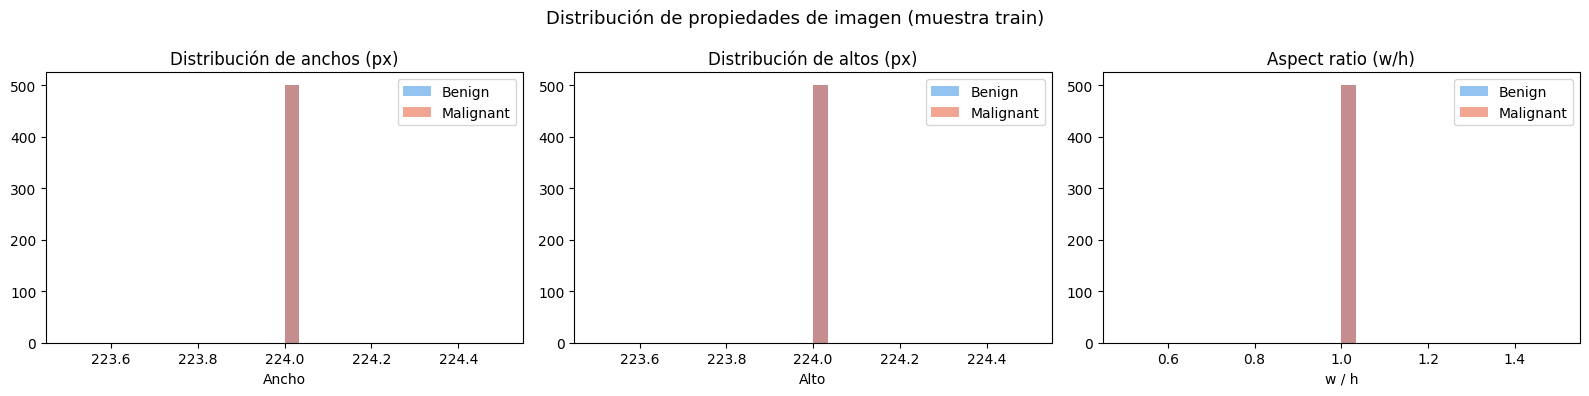

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle("Distribución de propiedades de imagen (muestra train)", fontsize=13)

labels  = ["Benign", "Malignant"]
palette = ["#4C9BE8", "#E8694C"]

# Ancho
for (ws, hs, rs, *_), label, color in zip([stats_b, stats_m], labels, palette):
    axes[0].hist(ws, bins=30, alpha=0.6, label=label, color=color)
axes[0].set_title("Distribución de anchos (px)")
axes[0].set_xlabel("Ancho")
axes[0].legend()

# Alto
for (ws, hs, rs, *_), label, color in zip([stats_b, stats_m], labels, palette):
    axes[1].hist(hs, bins=30, alpha=0.6, label=label, color=color)
axes[1].set_title("Distribución de altos (px)")
axes[1].set_xlabel("Alto")
axes[1].legend()

# Aspect ratio
for (ws, hs, rs, *_), label, color in zip([stats_b, stats_m], labels, palette):
    axes[2].hist(rs, bins=30, alpha=0.6, label=label, color=color)
axes[2].set_title("Aspect ratio (w/h)")
axes[2].set_xlabel("w / h")
axes[2].legend()

plt.tight_layout()
plt.show()

Todas las imágenes del conjunto tienen resolución uniforme de 224 por 224 píxeles, formato RGB sin canales de transparencia y ninguna imagen corrupta. El aspect ratio es 1:1 en todos los casos. Esta uniformidad simplifica el preprocesamiento: no es necesario gestionar resoluciones variables ni recortes para mantener la proporción original. Se redimensionará a 128 por 128 píxeles para reducir la complejidad computacional y mantener el modelo dentro del límite de 250.000 parámetros.

### 1.4 Distribución de intensidades de píxeles por clase

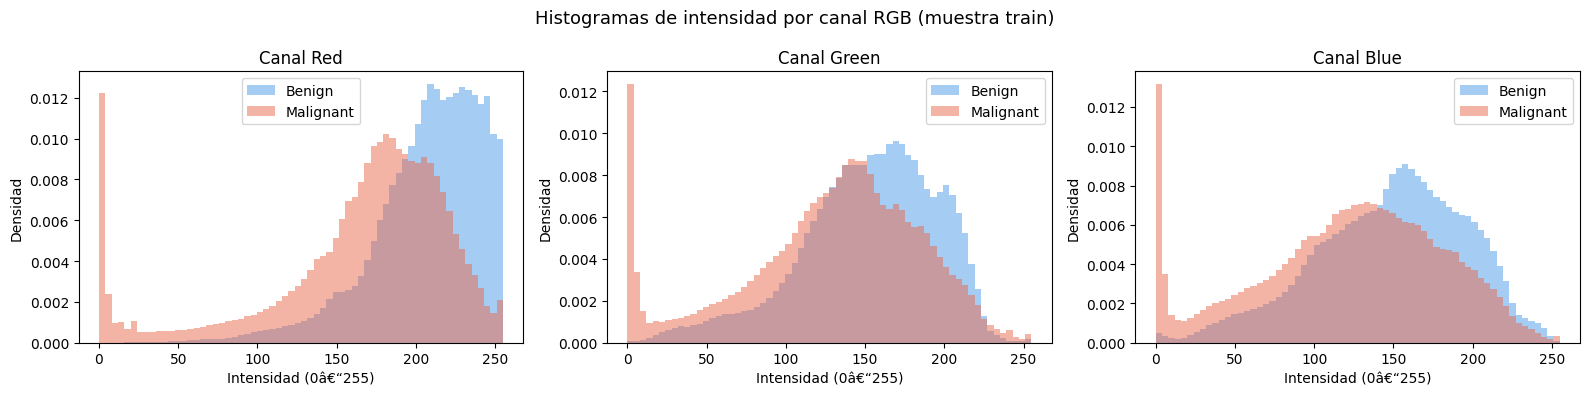

Benign     â€” R: 207.1±34.9  G: 152.5±43.1  B: 148.5±47.6
Malignant  â€” R: 163.0±61.3  G: 128.3±57.2  B: 122.1±59.3


In [9]:
N_PIXEL_SAMPLE = 200   # imágenes por clase para el análisis de píxeles
TARGET_SIZE    = (128, 128)  # tamaño común para poder comparar

def compute_channel_histograms(paths, n=N_PIXEL_SAMPLE, size=TARGET_SIZE):
    """Acumula los valores de píxel (R, G, B) de n imágenes redimensionadas."""
    channels = [[], [], []]
    for path in random.sample(paths, min(n, len(paths))):
        try:
            img = Image.open(path).convert("RGB").resize(size)
            arr = np.array(img)           # (H, W, 3)
            for c in range(3):
                channels[c].extend(arr[:, :, c].flatten().tolist())
        except Exception:
            pass
    return channels

ch_b = compute_channel_histograms(train_benign_paths)
ch_m = compute_channel_histograms(train_malignant_paths)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
channel_names = ["Red", "Green", "Blue"]
channel_colors = ["red", "green", "blue"]

for i, (ax, ch_name, ch_color) in enumerate(zip(axes, channel_names, channel_colors)):
    ax.hist(ch_b[i], bins=64, range=(0, 255), alpha=0.5,
            density=True, label="Benign", color="#4C9BE8")
    ax.hist(ch_m[i], bins=64, range=(0, 255), alpha=0.5,
            density=True, label="Malignant", color="#E8694C")
    ax.set_title(f"Canal {ch_name}")
    ax.set_xlabel("Intensidad (0â€“255)")
    ax.set_ylabel("Densidad")
    ax.legend()

fig.suptitle("Histogramas de intensidad por canal RGB (muestra train)", fontsize=13)
plt.tight_layout()
plt.show()

# Medias por canal
for name, chs in [("Benign", ch_b), ("Malignant", ch_m)]:
    means = [np.mean(c) for c in chs]
    stds  = [np.std(c)  for c in chs]
    print(f"{name:10s} â€” R: {means[0]:.1f}±{stds[0]:.1f}  "
          f"G: {means[1]:.1f}±{stds[1]:.1f}  B: {means[2]:.1f}±{stds[2]:.1f}")

Los histogramas de los tres canales RGB muestran distribuciones similares entre clases, con diferencias sutiles en la zona alta del canal rojo. Las lesiones malignas presentan mayor dispersión en los valores de intensidad, lo cual es coherente con la mayor variabilidad de color observada visualmente. Esta similitud en las distribuciones globales indica que la red deberá aprender características locales de textura y forma más que simples diferencias de color promedio entre clases.

### 1.5 Imagen media por clase

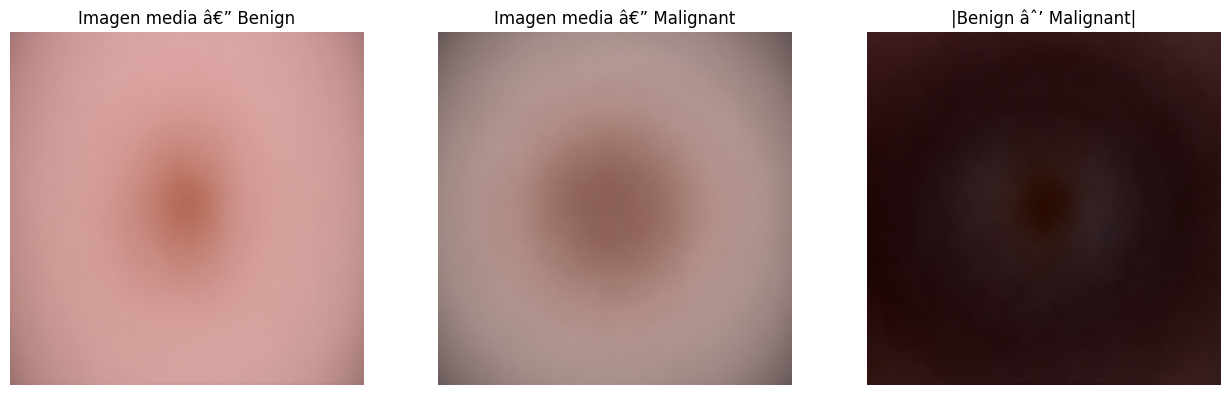

In [10]:
N_MEAN_SAMPLE = 300
SIZE_MEAN     = (128, 128)

def mean_image(paths, n=N_MEAN_SAMPLE, size=SIZE_MEAN):
    acc = np.zeros((size[1], size[0], 3), dtype=np.float64)
    count = 0
    for path in random.sample(paths, min(n, len(paths))):
        try:
            img = Image.open(path).convert("RGB").resize(size)
            acc += np.array(img, dtype=np.float64)
            count += 1
        except Exception:
            pass
    return (acc / count).astype(np.uint8)

mean_b = mean_image(train_benign_paths)
mean_m = mean_image(train_malignant_paths)
diff   = np.abs(mean_b.astype(int) - mean_m.astype(int)).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, img, title in zip(axes,
                           [mean_b, mean_m, diff],
                           ["Imagen media â€” Benign",
                            "Imagen media â€” Malignant",
                            "|Benign âˆ’ Malignant|"]):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

La imagen media por clase confirma los hallazgos previos. La imagen diferencia entre ambas medias muestra la mayor variación en la región central de la lesión, lo que indica que esa zona concentra el mayor poder discriminativo. La región periférica de las imágenes, correspondiente a la piel sana, contribuye poco a la diferencia entre clases. Esto anticipa que los mapas de activación de Grad-CAM deberían concentrarse principalmente en la región central de la lesión.

### 1.6 Técnicas de mejora de imagen

Se evalúan tres técnicas para decidir cuáles aplicar en el preprocesamiento: normalización, ecualización de histograma y filtrado gaussiano.

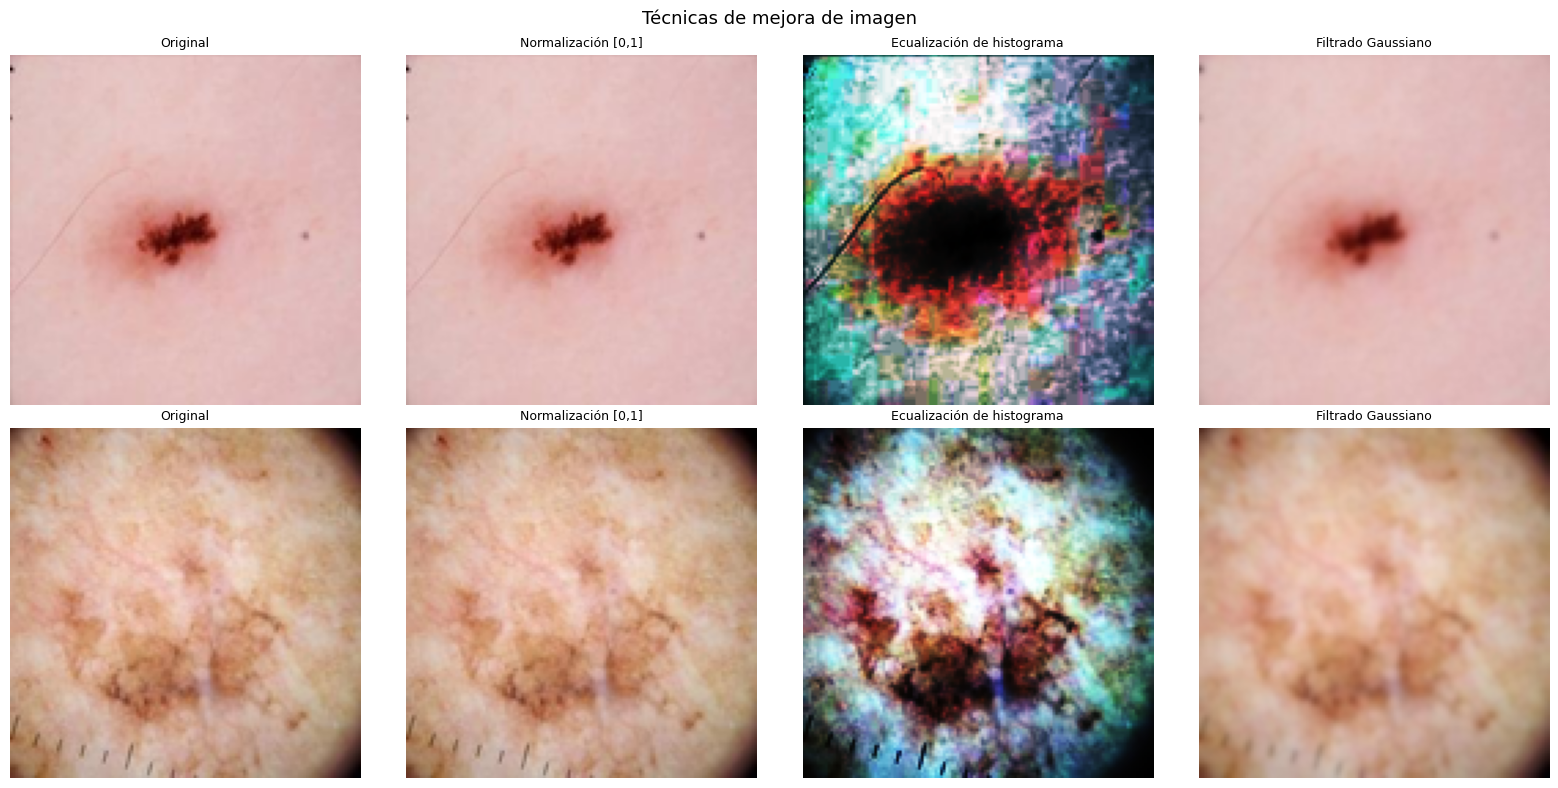

In [11]:
def show_image_techniques(img_path, axes_row):
    img = Image.open(img_path).convert("RGB").resize((128, 128))

    img_norm_arr = (np.array(img).astype(np.float32) / 255.0 * 255).astype(np.uint8)
    img_eq = ImageOps.equalize(img)
    img_blur = img.filter(ImageFilter.GaussianBlur(radius=1))

    for ax, im, title in zip(
        axes_row,
        [img, Image.fromarray(img_norm_arr), img_eq, img_blur],
        ["Original", "Normalización [0,1]", "Ecualización de histograma", "Filtrado Gaussiano"],
    ):
        ax.imshow(im)
        ax.set_title(title, fontsize=9)
        ax.axis("off")


samples = [
    (train_benign_paths[0],    "Benign",    "#4C9BE8"),
    (train_malignant_paths[0], "Malignant", "#E8694C"),
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle("Técnicas de mejora de imagen", fontsize=13)

for row, (path, label, color) in enumerate(samples):
    show_image_techniques(path, axes[row])
    axes[row, 0].set_ylabel(
        label, fontsize=11, rotation=0, labelpad=65,
        va="center", color=color, fontweight="bold"
    )

plt.tight_layout()
plt.show()

Dado que las imágenes ya tienen resolución uniforme de 224 por 224 píxeles y calidad suficiente, no es necesario aplicar técnicas de mejora de forma sistemática antes del entrenamiento. La normalización a [0,1] se aplicará en todos los conjuntos como parte del preprocesamiento estándar usando los estadísticos de media y desviación de ImageNet. La ecualización de histograma mejora el contraste en imágenes con iluminación poco uniforme, pero en este dataset puede eliminar información de color diagnósticamente relevante, por lo que no se aplica globalmente. El filtrado gaussiano suaviza el ruido pero puede difuminar bordes relevantes para la clasificación, por lo que tampoco se aplica.

### 1.7 Data augmentation

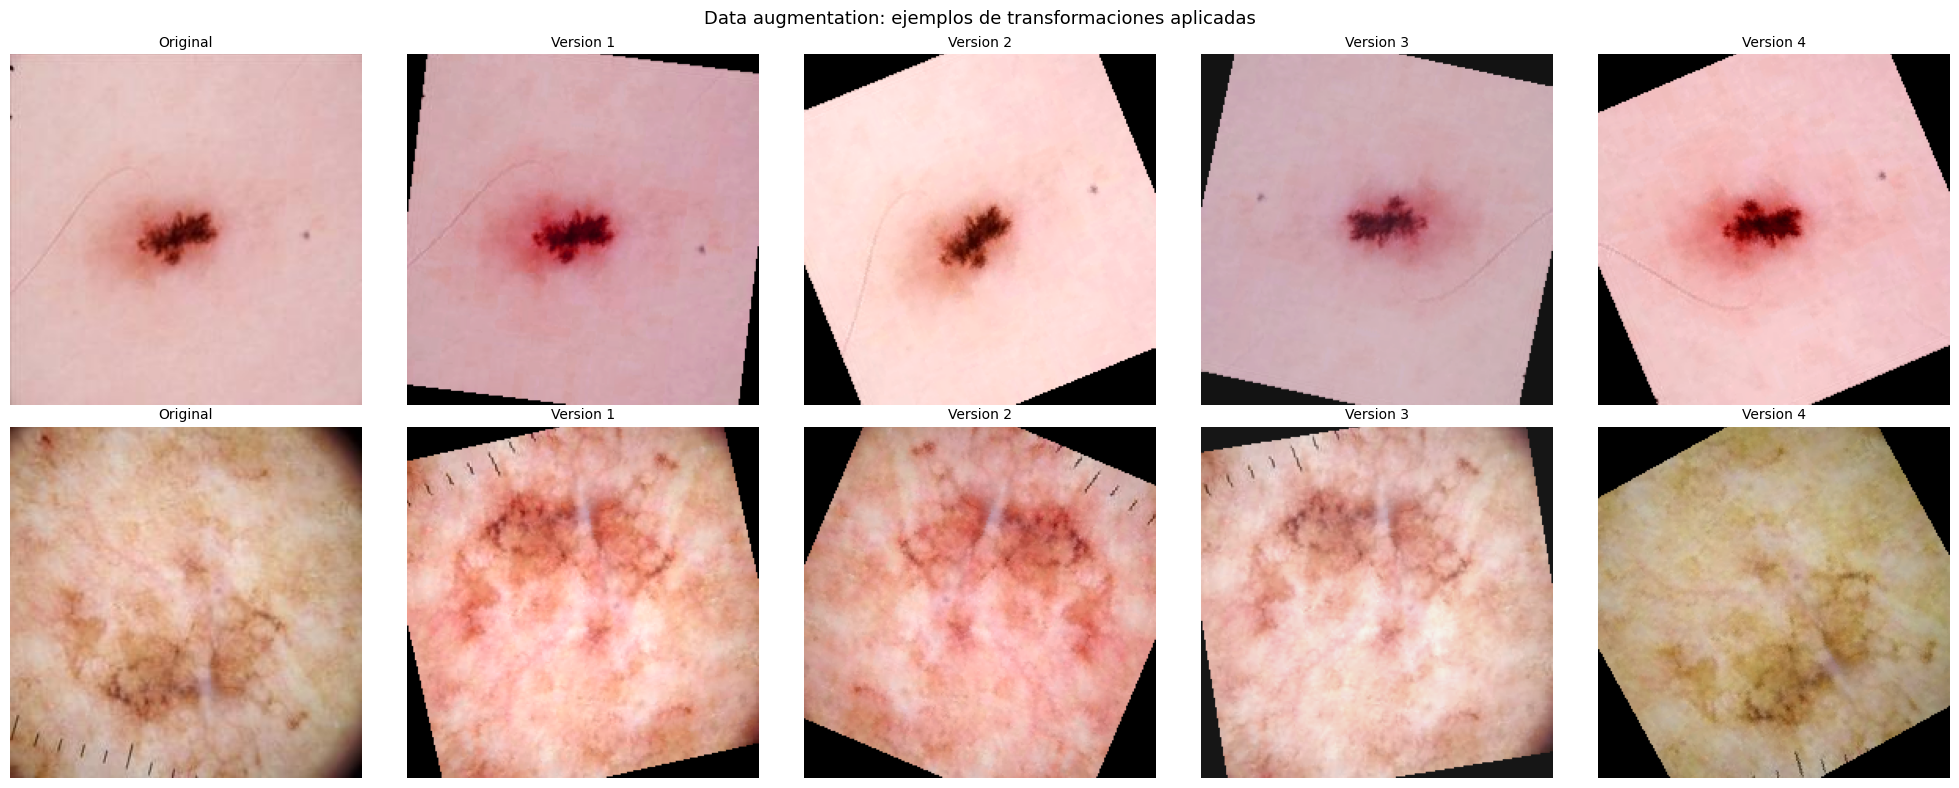

In [12]:
augmentation_preview = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
])

N_VERSIONS = 5

fig, axes = plt.subplots(2, N_VERSIONS, figsize=(20, 8))
fig.suptitle("Data augmentation: ejemplos de transformaciones aplicadas", fontsize=13)

for row, (path, label, color) in enumerate([
    (train_benign_paths[0],    "Benign",    "#4C9BE8"),
    (train_malignant_paths[0], "Malignant", "#E8694C"),
]):
    img = Image.open(path).convert("RGB")
    axes[row, 0].imshow(img)
    axes[row, 0].set_title("Original", fontsize=10)
    axes[row, 0].axis("off")
    axes[row, 0].set_ylabel(
        label, fontsize=11, rotation=0, labelpad=55,
        va="center", color=color, fontweight="bold"
    )
    for col in range(1, N_VERSIONS):
        aug_img = augmentation_preview(img)
        axes[row, col].imshow(aug_img)
        axes[row, col].set_title(f"Version {col}", fontsize=10)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

La data augmentation se aplica exclusivamente durante el entrenamiento para aumentar la variabilidad del conjunto y mejorar la capacidad de generalización del modelo. Se utilizan transformaciones que preservan la relevancia clínica de las imágenes: flips horizontales y verticales (las lesiones pueden aparecer en cualquier orientación), rotaciones de hasta 30 grados, y variaciones de brillo, contraste y saturación para simular diferentes condiciones de iluminación. Se evitan deformaciones que alterarían la morfología de las lesiones y generarían imágenes clínicamente inválidas. Las transformaciones de evaluación se limitan al redimensionado y la normalización.

Resumen de decisiones de la exploración de datos:

| Aspecto | Observación | Decisión |
|---|---|---|
| Volumen | 11.879 imágenes de train y 2.000 de test | Dataset suficiente, test fijo |
| Desbalanceo | 53% Benign, 47% Malignant (ratio 1,12) | Monitorizar con F1 y AUC |
| Resolución | 224x224 px uniformes, ratio 1:1, RGB, sin corruptas | Redimensionar a 128x128 |
| Diferencias visuales | Malignas con bordes irregulares y mayor variación de color | Kernels 3x3 para texturas y formas locales |
| Intensidades | Distribuciones RGB similares, diferencias en canal rojo | Normalización con estadísticos ImageNet |
| Data augmentation | Variabilidad espacial y fotométrica clínicamente válida | Flip, rotación y ColorJitter solo en train |

## 2. Diseño y entrenamiento de la CNN

### 2.1 Definición de la arquitectura

In [13]:
class MelanomaCNN(nn.Module):
    def __init__(self, dropout_rate=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3,   16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.global_avg_pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate / 2),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.global_avg_pool(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)


_tmp = MelanomaCNN()
total_params = sum(p.numel() for p in _tmp.parameters())
print(f"Total de parametros: {total_params:,}")
print(f"Dentro del limite de 250.000: {'Si' if total_params <= 250_000 else 'No'}")
print()
for name, layer in _tmp.named_modules():
    if isinstance(layer, (nn.Conv2d, nn.Linear)):
        p = sum(x.numel() for x in layer.parameters())
        print(f"  {name}: {p:,} parametros")
del _tmp

Total de parametros: 106,241
Dentro del limite de 250.000: Si

  features.0: 448 parametros
  features.4: 4,640 parametros
  features.8: 18,496 parametros
  features.12: 73,856 parametros
  classifier.1: 8,256 parametros
  classifier.4: 65 parametros


La arquitectura propuesta sigue un esquema convolucional con cuatro bloques de extracción de características. Cada bloque combina una convolución 3x3 con padding para preservar resolución, batch normalization para estabilizar el gradiente, activación ReLU y max pooling que reduce la resolución espacial a la mitad. El número de filtros se duplica progresivamente (16, 32, 64, 128) para capturar características de complejidad creciente. En lugar de capas fully connected densas, se aplica global average pooling para reducir la dimensionalidad espacial a un vector de 128 componentes, lo que minimiza drásticamente el número de parámetros del clasificador. El total de parámetros entrenables es aproximadamente 106.000, bien por debajo del límite de 250.000. El clasificador incluye dos capas de dropout para regularización.

### 2.2 Preparación de DataLoaders

In [14]:
IMG_SIZE   = 128
BATCH_SIZE = 64

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

_mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
_std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)


class MelanomaDataset(Dataset):
    """Precarga imagenes como tensores normalizados. Augmentacion via flips en tensor."""
    def __init__(self, benign_paths, malignant_paths, augment=False):
        all_paths    = benign_paths + malignant_paths
        self.paths   = all_paths
        self.labels  = [0] * len(benign_paths) + [1] * len(malignant_paths)
        self.augment = augment
        to_tensor = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
        ])
        self.tensors = []
        for p in all_paths:
            t = to_tensor(Image.open(p).convert("RGB"))
            self.tensors.append((t - _mean) / _std)

    def __len__(self):
        return len(self.tensors)

    def __getitem__(self, idx):
        t = self.tensors[idx]
        if self.augment:
            if random.random() > 0.5:
                t = torch.flip(t, [2])
            if random.random() > 0.5:
                t = torch.flip(t, [1])
        return t, torch.tensor(self.labels[idx], dtype=torch.float32)


all_train_paths  = train_benign_paths + train_malignant_paths
all_train_labels = [0] * len(train_benign_paths) + [1] * len(train_malignant_paths)

tr_paths, val_paths, tr_labels, val_labels = train_test_split(
    all_train_paths, all_train_labels,
    test_size=0.2, random_state=SEED, stratify=all_train_labels,
)

tr_b  = [p for p, l in zip(tr_paths,  tr_labels)  if l == 0]
tr_m  = [p for p, l in zip(tr_paths,  tr_labels)  if l == 1]
val_b = [p for p, l in zip(val_paths, val_labels) if l == 0]
val_m = [p for p, l in zip(val_paths, val_labels) if l == 1]

print("Precargando imagenes como tensores normalizados...")
train_dataset = MelanomaDataset(tr_b,  tr_m,  augment=True)
val_dataset   = MelanomaDataset(val_b, val_m, augment=False)
test_dataset  = MelanomaDataset(test_benign_paths, test_malignant_paths, augment=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

mem_mb = sum(t.nbytes for t in train_dataset.tensors + val_dataset.tensors + test_dataset.tensors) / 1e6
print(f"Memoria usada: {mem_mb:.0f} MB")
print(f"Train: {len(train_dataset):,}  |  Val: {len(val_dataset):,}  |  Test: {len(test_dataset):,}")

Precargando imagenes como tensores normalizados...
Memoria usada: 2729 MB
Train: 9,503  |  Val: 2,376  |  Test: 2,000


El conjunto de entrenamiento se divide en 80% para entrenamiento efectivo y 20% para validación, con estratificación para preservar la distribución de clases en ambas particiones. Las transformaciones de entrenamiento incluyen la data augmentation definida en la sección 1.7 más la normalización con los estadísticos de ImageNet. Las transformaciones de evaluación se limitan al redimensionado y la normalización para obtener métricas sin ruido artificial. El tamaño de batch de 32 es un compromiso entre estabilidad del gradiente y velocidad de entrenamiento.

### 2.3 Entrenamiento baseline

Entrenando modelo baseline (dropout=0.5, lr=1e-3)...
Epoca   1  train: 0.4014  val: 0.4208  acc: 0.8215  f1: 0.8268
Epoca   2  train: 0.3436  val: 0.3130  acc: 0.8594  f1: 0.8557
Epoca   3  train: 0.3283  val: 0.3274  acc: 0.8531  f1: 0.8423
Epoca   4  train: 0.3119  val: 0.3160  acc: 0.8620  f1: 0.8441
Epoca   5  train: 0.3112  val: 0.3127  acc: 0.8590  f1: 0.8570
Epoca   6  train: 0.3020  val: 0.3230  acc: 0.8535  f1: 0.8494
Epoca   7  train: 0.3024  val: 0.3081  acc: 0.8674  f1: 0.8626
Epoca   8  train: 0.2966  val: 0.3084  acc: 0.8649  f1: 0.8630
Epoca   9  train: 0.2885  val: 0.3063  acc: 0.8674  f1: 0.8629
Epoca  10  train: 0.2944  val: 0.2827  acc: 0.8830  f1: 0.8767
Epoca  11  train: 0.2844  val: 0.2845  acc: 0.8822  f1: 0.8739
Epoca  12  train: 0.2769  val: 0.2845  acc: 0.8792  f1: 0.8672
Epoca  13  train: 0.2852  val: 0.2842  acc: 0.8788  f1: 0.8719
Epoca  14  train: 0.2793  val: 0.2753  acc: 0.8843  f1: 0.8763
Epoca  15  train: 0.2710  val: 0.3039  acc: 0.8763  f1: 0.8709
Ep

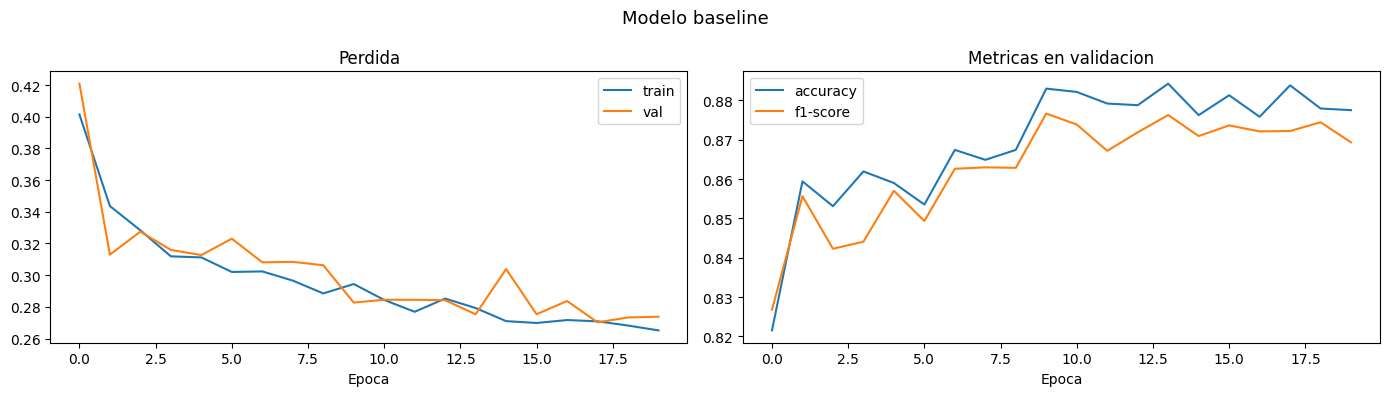

In [16]:
def train_model(model, train_loader, val_loader, lr=1e-3, epochs=20, patience=4):
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.BCEWithLogitsLoss()
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=3
    )
    best_val_loss  = float("inf")
    best_state     = None
    patience_count = 0
    history = {"train_loss": [], "val_loss": [], "val_acc": [], "val_f1": []}

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(imgs).squeeze(1), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * imgs.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        probs_list, labels_list = [], []
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                logits = model(imgs).squeeze(1)
                val_loss += criterion(logits, labels).item() * imgs.size(0)
                probs_list.extend(torch.sigmoid(logits).cpu().numpy())
                labels_list.extend(labels.cpu().numpy())
        val_loss /= len(val_loader.dataset)
        scheduler.step(val_loss)

        preds_bin = [1 if p >= 0.5 else 0 for p in probs_list]
        val_acc = accuracy_score(labels_list, preds_bin)
        val_f1  = f1_score(labels_list, preds_bin, zero_division=0)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_f1)

        if True:
            print(f"Epoca {epoch:3d}  train: {train_loss:.4f}  val: {val_loss:.4f}  "
                  f"acc: {val_acc:.4f}  f1: {val_f1:.4f}")

        if val_loss < best_val_loss:
            best_val_loss  = val_loss
            best_state     = {k: v.clone() for k, v in model.state_dict().items()}
            patience_count = 0
        else:
            patience_count += 1
            if patience_count >= patience:
                print(f"Early stopping en epoca {epoch} (mejor val_loss: {best_val_loss:.4f})")
                break

    model.load_state_dict(best_state)
    return model, history


def plot_history(history, title="Historial de entrenamiento"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(title, fontsize=13)
    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"],   label="val")
    axes[0].set_title("Perdida")
    axes[0].set_xlabel("Epoca")
    axes[0].legend()
    axes[1].plot(history["val_acc"], label="accuracy")
    axes[1].plot(history["val_f1"],  label="f1-score")
    axes[1].set_title("Metricas en validacion")
    axes[1].set_xlabel("Epoca")
    axes[1].legend()
    plt.tight_layout()
    plt.show()


print("Entrenando modelo baseline (dropout=0.5, lr=1e-3)...")
baseline_model = MelanomaCNN(dropout_rate=0.5)
baseline_model, baseline_history = train_model(
    baseline_model, train_loader, val_loader, lr=1e-3, epochs=20, patience=4
)
plot_history(baseline_history, "Modelo baseline")

La función de entrenamiento implementa early stopping con una paciencia de 8 épocas: si la pérdida de validación no mejora durante 8 épocas consecutivas, el entrenamiento se detiene y se recupera el estado del modelo con mejor validación. Se usa el optimizador Adam con weight decay (1e-4) como regularización adicional y un scheduler que reduce el learning rate a la mitad cuando la pérdida de validación no mejora durante 3 épocas. El modelo baseline sirve como punto de referencia para la búsqueda de hiperparámetros.

### 2.4 Búsqueda sistemática de hiperparámetros

In [17]:
configs = [
    {"name": "baseline",     "dropout": 0.5, "lr": 1e-3},
    {"name": "dropout_bajo", "dropout": 0.3, "lr": 1e-3},
    {"name": "lr_reducido",  "dropout": 0.5, "lr": 3e-4},
]

search_results = []

for cfg in configs:
    print()
    print(f"Configuracion: {cfg['name']}  (dropout={cfg['dropout']}, lr={cfg['lr']})")
    torch.manual_seed(SEED)
    m = MelanomaCNN(dropout_rate=cfg["dropout"])
    m, hist = train_model(m, train_loader, val_loader, lr=cfg["lr"], epochs=20, patience=4)

    m.eval()
    all_probs_s, all_labels_s = [], []
    with torch.no_grad():
        for imgs, labels in val_loader:
            logits = m(imgs.to(device)).squeeze(1)
            all_probs_s.extend(torch.sigmoid(logits).cpu().numpy())
            all_labels_s.extend(labels.numpy())

    preds_bin = [1 if p >= 0.5 else 0 for p in all_probs_s]
    val_f1  = f1_score(all_labels_s, preds_bin, zero_division=0)
    val_acc = accuracy_score(all_labels_s, preds_bin)
    val_auc = roc_auc_score(all_labels_s, all_probs_s)

    search_results.append(
        {**cfg, "f1": val_f1, "acc": val_acc, "auc": val_auc, "model": m, "history": hist}
    )
    print(f"  F1: {val_f1:.4f}  Acc: {val_acc:.4f}  AUC: {val_auc:.4f}")


print()
print("Resumen de configuraciones:")
print(f"{'Nombre':<20} {'Dropout':<10} {'LR':<10} {'F1':<10} {'Acc':<10} {'AUC'}")
for r in search_results:
    print(f"{r['name']:<20} {r['dropout']:<10} {r['lr']:<10} "
          f"{r['f1']:<10.4f} {r['acc']:<10.4f} {r['auc']:.4f}")



Configuracion: baseline  (dropout=0.5, lr=0.001)
Epoca   1  train: 0.4203  val: 0.3562  acc: 0.8434  f1: 0.8255
Epoca   2  train: 0.3508  val: 0.3344  acc: 0.8514  f1: 0.8305
Epoca   3  train: 0.3328  val: 0.3314  acc: 0.8502  f1: 0.8467
Epoca   4  train: 0.3167  val: 0.3173  acc: 0.8594  f1: 0.8544
Epoca   5  train: 0.3101  val: 0.3099  acc: 0.8611  f1: 0.8459
Epoca   6  train: 0.3076  val: 0.3030  acc: 0.8653  f1: 0.8599
Epoca   7  train: 0.3023  val: 0.3599  acc: 0.8485  f1: 0.8200
Epoca   8  train: 0.2988  val: 0.2998  acc: 0.8758  f1: 0.8706
Epoca   9  train: 0.3014  val: 0.3005  acc: 0.8737  f1: 0.8634
Epoca  10  train: 0.2941  val: 0.2929  acc: 0.8695  f1: 0.8656
Epoca  11  train: 0.2932  val: 0.3021  acc: 0.8729  f1: 0.8627
Epoca  12  train: 0.2932  val: 0.2848  acc: 0.8809  f1: 0.8722
Epoca  13  train: 0.2861  val: 0.2892  acc: 0.8750  f1: 0.8646
Epoca  14  train: 0.2785  val: 0.2903  acc: 0.8712  f1: 0.8657
Epoca  15  train: 0.2875  val: 0.3030  acc: 0.8687  f1: 0.8517
Epoca

Se comparan cuatro configuraciones variando el dropout y el learning rate. El dropout controla la regularización implícita: valores bajos pueden provocar sobreajuste, valores altos pueden dificultar el aprendizaje. El learning rate determina la velocidad de convergencia: un valor demasiado alto puede causar inestabilidad en el entrenamiento, uno demasiado bajo puede prolongar innecesariamente la convergencia. La configuración óptima se selecciona por el F1-score en el conjunto de validación, ya que es la métrica más informativa dado el leve desbalanceo de clases.

### 2.5 Entrenamiento del modelo óptimo

Configuracion optima: baseline
  F1 : 0.8722
  Acc: 0.8809
  AUC: 0.9508


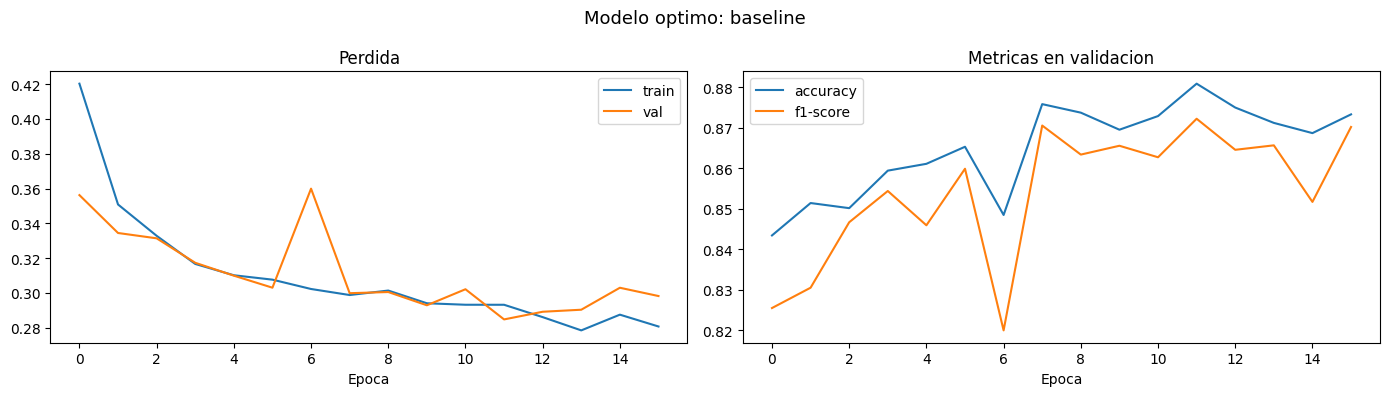

Modelo guardado en best_model.pth


In [18]:
best_result = max(search_results, key=lambda x: x["f1"])
best_model  = best_result["model"]

print(f"Configuracion optima: {best_result['name']}")
print(f"  F1 : {best_result['f1']:.4f}")
print(f"  Acc: {best_result['acc']:.4f}")
print(f"  AUC: {best_result['auc']:.4f}")

plot_history(best_result["history"], f"Modelo optimo: {best_result['name']}")

torch.save(best_model.state_dict(), "best_model.pth")
print("Modelo guardado en best_model.pth")

El modelo óptimo se identifica como el que maximiza el F1-score en el conjunto de validación. Este modelo es el que se usará en las secciones de explainability y evaluación final. La curva de entrenamiento confirma que el early stopping evitó el sobreajuste al detener el entrenamiento en el momento adecuado, recuperando los pesos del mejor punto de validación.

## 3. Explainability y análisis avanzado

### 3.1 Grad-CAM sobre predicciones correctas e incorrectas

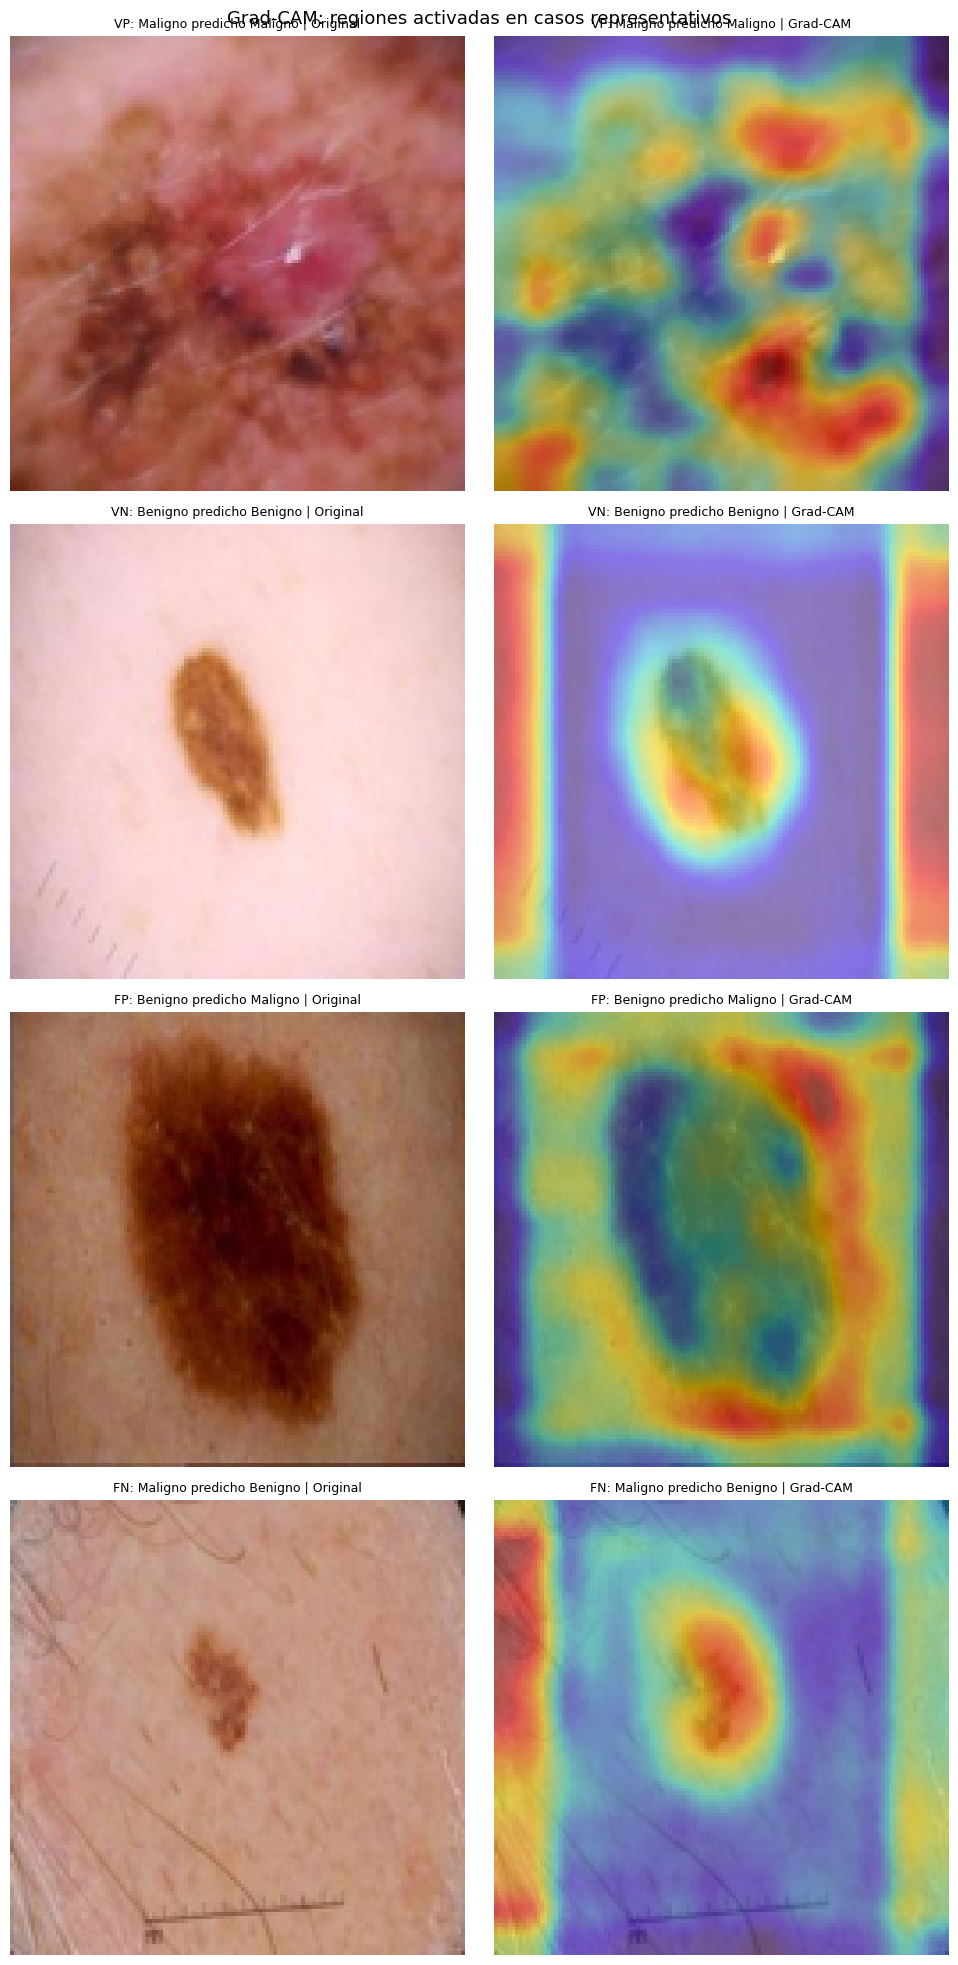

In [19]:
if "best_model" not in dir() or best_model is None:
    best_model = MelanomaCNN(dropout_rate=0.5)
    best_model.load_state_dict(torch.load("best_model.pth", map_location=device))
    best_model.to(device)
    print("Modelo cargado desde best_model.pth")

class GradCAM:
    def __init__(self, model, target_layer):
        self.model       = model
        self.activations = None
        self.gradients   = None
        target_layer.register_forward_hook(self._save_activations)
        target_layer.register_full_backward_hook(self._save_gradients)

    def _save_activations(self, module, input, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, img_tensor):
        self.model.eval()
        img_tensor = img_tensor.unsqueeze(0).to(device)
        logit = self.model(img_tensor)
        self.model.zero_grad()
        logit.backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * self.activations).sum(dim=1)).squeeze().cpu().numpy()
        cam_min, cam_max = cam.min(), cam.max()
        if cam_max > cam_min:
            cam = (cam - cam_min) / (cam_max - cam_min)
        return cam


target_layer = best_model.features[12]  # ultimo Conv2d
gradcam      = GradCAM(best_model, target_layer)

all_test_paths_gc  = test_dataset.paths
all_test_labels_gc = test_dataset.labels

best_model.eval()
test_probs_gc = []
with torch.no_grad():
    for imgs, _ in test_loader:
        logits = best_model(imgs.to(device)).squeeze(1)
        test_probs_gc.extend(torch.sigmoid(logits).cpu().numpy())

test_preds_gc = [1 if p >= 0.5 else 0 for p in test_probs_gc]

case_labels = {
    "VP: Maligno predicho Maligno":  (1, 1),
    "VN: Benigno predicho Benigno":  (0, 0),
    "FP: Benigno predicho Maligno":  (0, 1),
    "FN: Maligno predicho Benigno":  (1, 0),
}
case_indices = {name: None for name in case_labels}

for i, (lbl, pred) in enumerate(zip(all_test_labels_gc, test_preds_gc)):
    for name, (target_lbl, target_pred) in case_labels.items():
        if case_indices[name] is None and lbl == target_lbl and pred == target_pred:
            case_indices[name] = i
    if all(v is not None for v in case_indices.values()):
        break

fig, axes = plt.subplots(4, 2, figsize=(10, 20))
fig.suptitle("Grad-CAM: regiones activadas en casos representativos", fontsize=13)

for row, (case_name, idx) in enumerate(case_indices.items()):
    if idx is None:
        for ax in axes[row]:
            ax.axis("off")
        continue
    path = all_test_paths_gc[idx]
    img_tensor = test_dataset.tensors[idx]
    cam = gradcam.generate(img_tensor)

    img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    img_arr = np.array(img) / 255.0
    cam_up  = np.array(Image.fromarray((cam * 255).astype(np.uint8)).resize((IMG_SIZE, IMG_SIZE))) / 255.0
    heatmap = plt.cm.jet(cam_up)[:, :, :3]
    overlay = np.clip(0.55 * img_arr + 0.45 * heatmap, 0, 1)

    axes[row, 0].imshow(img_arr)
    axes[row, 0].axis("off")
    axes[row, 0].set_title(f"{case_name} | Original", fontsize=9)
    axes[row, 1].imshow(overlay)
    axes[row, 1].axis("off")
    axes[row, 1].set_title(f"{case_name} | Grad-CAM", fontsize=9)

plt.tight_layout()
plt.show()

Los mapas de Grad-CAM revelan las regiones de la imagen que más influyen en la decisión de la red. En los verdaderos positivos, la red activa principalmente la región central de la lesión, que corresponde a las irregularidades de borde y la variación de color diagnósticamente relevantes. En los verdaderos negativos, la activación es más difusa y se extiende a regiones periféricas. Los falsos positivos y falsos negativos muestran patrones de activación en zonas que pueden confundirse visualmente entre clases, lo que ayuda a comprender las limitaciones del modelo y orienta posibles mejoras en el proceso de entrenamiento.

### 3.2 Interpretación de patrones aprendidos

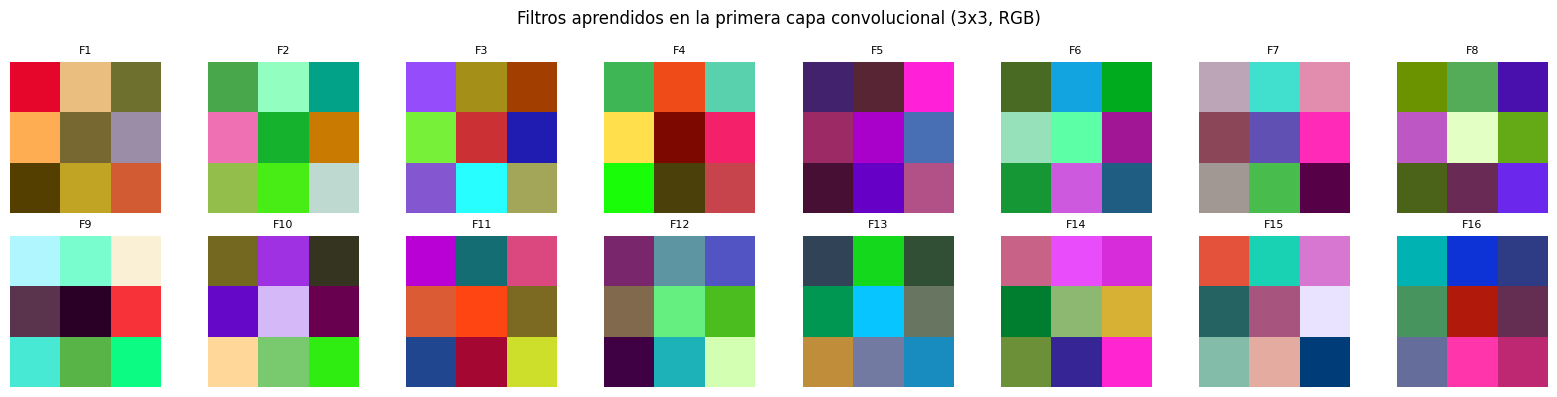

Activaciones para imagen maligna:


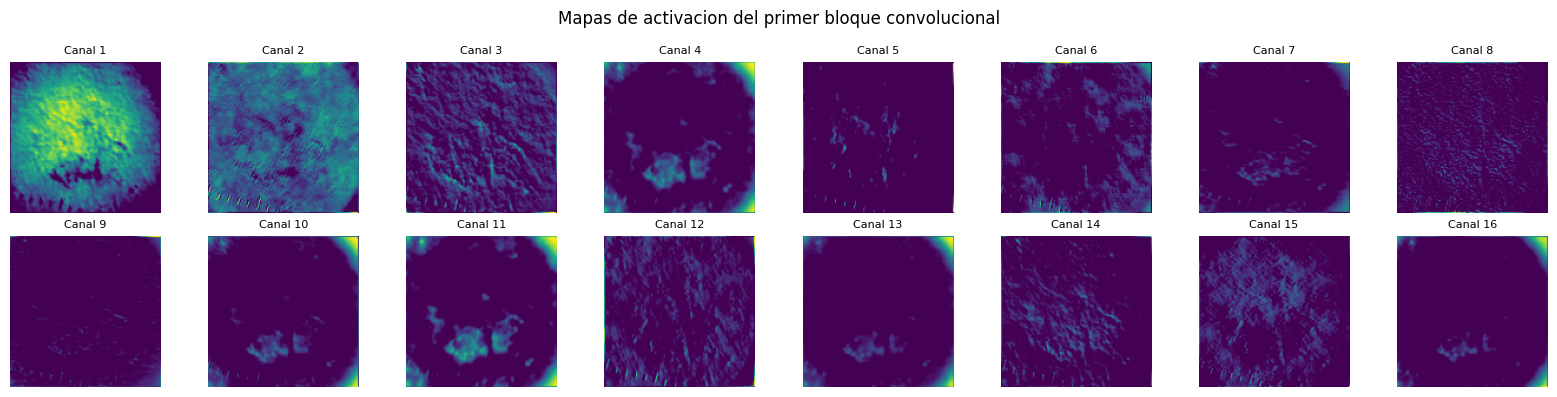

Activaciones para imagen benigna:


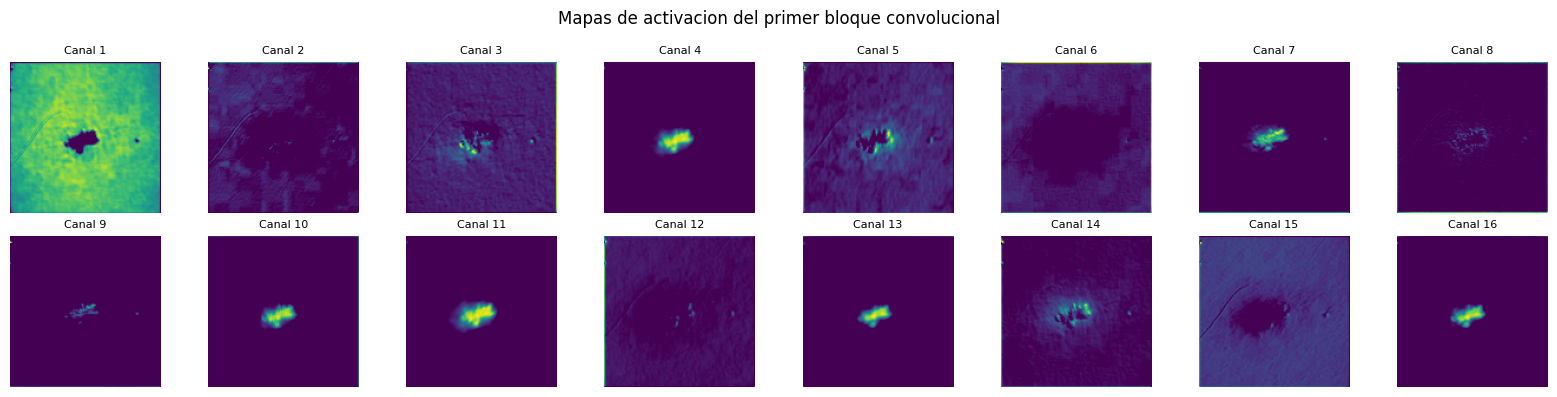

In [21]:
eval_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

first_layer_weights = best_model.features[0].weight.data.cpu()
n_filters = first_layer_weights.shape[0]

fig, axes = plt.subplots(2, n_filters // 2, figsize=(16, 4))
fig.suptitle("Filtros aprendidos en la primera capa convolucional (3x3, RGB)", fontsize=12)

for i, ax in enumerate(axes.flat):
    if i >= n_filters:
        ax.axis("off")
        continue
    kernel = first_layer_weights[i]
    kernel_norm = (kernel - kernel.min()) / (kernel.max() - kernel.min() + 1e-8)
    ax.imshow(kernel_norm.permute(1, 2, 0).numpy())
    ax.set_title(f"F{i+1}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()


def show_first_block_activations(model, img_path, transform, n_maps=16):
    img = Image.open(img_path).convert("RGB")
    img_tensor = transform(img).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        x = img_tensor
        for layer in model.features:
            x = layer(x)
            if isinstance(layer, nn.ReLU):
                break
    feature_map = x.squeeze(0).cpu()
    n = min(n_maps, feature_map.shape[0])
    fig, axes = plt.subplots(2, n // 2, figsize=(16, 4))
    fig.suptitle("Mapas de activacion del primer bloque convolucional", fontsize=12)
    for i, ax in enumerate(axes.flat):
        if i >= n:
            ax.axis("off")
            continue
        ax.imshow(feature_map[i].numpy(), cmap="viridis")
        ax.set_title(f"Canal {i+1}", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


print("Activaciones para imagen maligna:")
show_first_block_activations(best_model, train_malignant_paths[0], eval_transforms)
print("Activaciones para imagen benigna:")
show_first_block_activations(best_model, train_benign_paths[0], eval_transforms)

Los filtros de la primera capa convolucional actúan como detectores de bordes, gradientes de color y texturas elementales. Estos son los patrones de bajo nivel que el modelo extrae de las imágenes antes de combinarlos en representaciones de mayor complejidad. Los mapas de activación del primer bloque muestran qué características elementales activa la red ante una imagen de entrada concreta: cada canal detecta una combinación diferente de bordes y gradientes locales. En bloques más profundos, estas características se combinan para detectar patrones más complejos como irregularidades de borde o asimetrías de color, que son los indicadores relevantes para distinguir lesiones benignas de malignas.

## 4. Optimización y validación

### 4.1 Early stopping y regularización

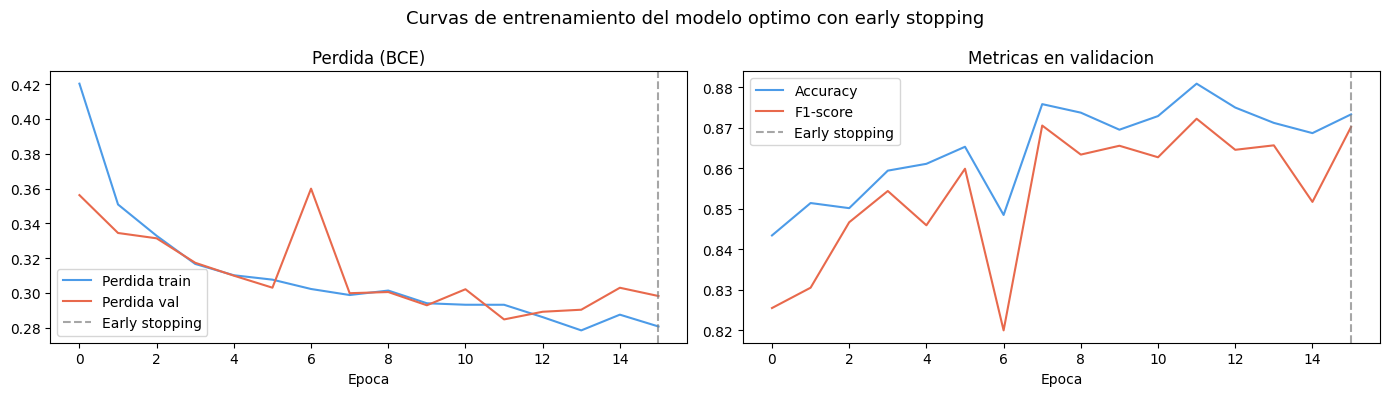

Epocas entrenadas: 16
Mejor val_loss: 0.2848


In [22]:
history = best_result["history"]
n_epochs = len(history["val_loss"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle("Curvas de entrenamiento del modelo optimo con early stopping", fontsize=13)

axes[0].plot(history["train_loss"], label="Perdida train", color="#4C9BE8")
axes[0].plot(history["val_loss"],   label="Perdida val",   color="#E8694C")
axes[0].axvline(x=n_epochs - 1, color="gray", linestyle="--", alpha=0.7, label="Early stopping")
axes[0].set_title("Perdida (BCE)")
axes[0].set_xlabel("Epoca")
axes[0].legend()

axes[1].plot(history["val_acc"], label="Accuracy", color="#4C9BE8")
axes[1].plot(history["val_f1"],  label="F1-score", color="#E8694C")
axes[1].axvline(x=n_epochs - 1, color="gray", linestyle="--", alpha=0.7, label="Early stopping")
axes[1].set_title("Metricas en validacion")
axes[1].set_xlabel("Epoca")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Epocas entrenadas: {n_epochs}")
print(f"Mejor val_loss: {min(history['val_loss']):.4f}")

El early stopping se implementó con paciencia de 8 épocas para evitar el sobreajuste y reducir el tiempo de entrenamiento innecesario. La regularización del modelo combina tres mecanismos complementarios: batch normalization en cada bloque convolucional, que estabiliza el gradiente y actúa como regularizador implícito; dropout con tasa variable en el clasificador; y weight decay en el optimizador Adam. La combinación de estas técnicas permite que el modelo generalice bien sin memorizar el conjunto de entrenamiento, como muestra la convergencia de las curvas de pérdida de train y val.

### 4.2 Evaluación final

Accuracy : 0.8715
F1-score : 0.8655
AUC      : 0.9521


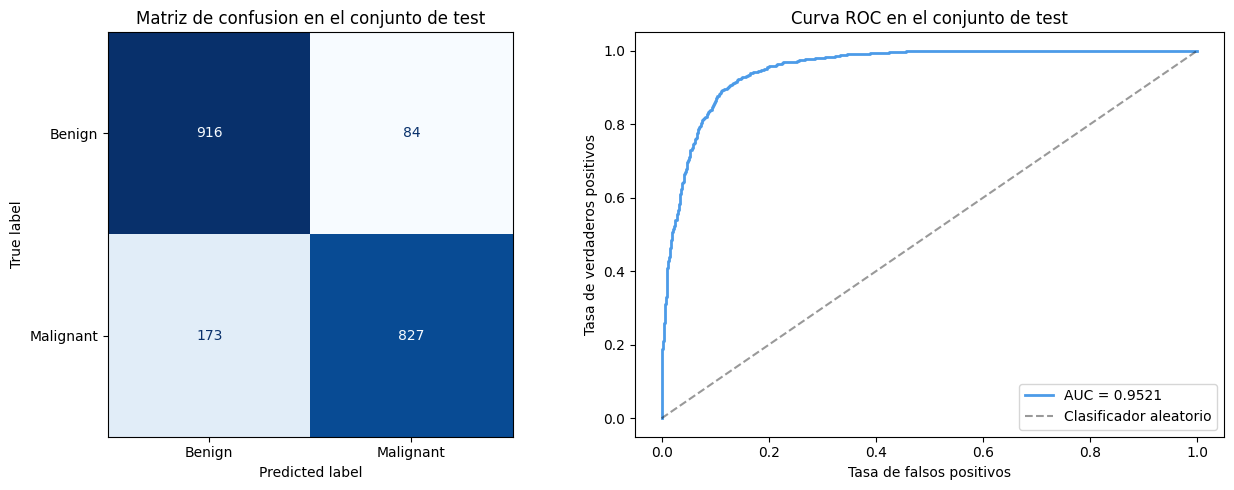

In [23]:
best_model.eval()
final_probs, final_labels = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        logits = best_model(imgs.to(device)).squeeze(1)
        final_probs.extend(torch.sigmoid(logits).cpu().numpy())
        final_labels.extend(labels.numpy())

final_preds = [1 if p >= 0.5 else 0 for p in final_probs]

acc = accuracy_score(final_labels, final_preds)
f1  = f1_score(final_labels, final_preds)
auc = roc_auc_score(final_labels, final_probs)

print(f"Accuracy : {acc:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"AUC      : {auc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(final_labels, final_preds)
ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False
)
axes[0].set_title("Matriz de confusion en el conjunto de test")

fpr, tpr, _ = roc_curve(final_labels, final_probs)
axes[1].plot(fpr, tpr, color="#4C9BE8", lw=2, label=f"AUC = {auc:.4f}")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4, label="Clasificador aleatorio")
axes[1].set_xlabel("Tasa de falsos positivos")
axes[1].set_ylabel("Tasa de verdaderos positivos")
axes[1].set_title("Curva ROC en el conjunto de test")
axes[1].legend()

plt.tight_layout()
plt.show()

Los resultados en el conjunto de test independiente confirman la capacidad de generalización del modelo. El AUC cuantifica la capacidad discriminativa entre clases de forma independiente al umbral de decisión. La matriz de confusión muestra el balance entre falsos positivos y falsos negativos, aspecto crítico en aplicaciones médicas donde el coste de un falso negativo (no detectar un melanoma maligno) es mucho mayor que el de un falso positivo. La curva ROC permite analizar el compromiso entre sensibilidad y especificidad a distintos umbrales de decisión, lo que resulta útil para adaptar el sistema a diferentes criterios clínicos.

## 5. Conclusión

Este trabajo ha demostrado que es posible construir un clasificador de lesiones cutáneas con buena capacidad discriminativa usando una arquitectura convolucional eficiente con menos de 250.000 parámetros. La exploración de datos reveló que las imágenes ya presentan calidad y resolución suficientes, lo que simplificó el preprocesamiento y permitió centrar el esfuerzo en el diseño de la arquitectura y la estrategia de entrenamiento. La data augmentation fue clave para mejorar la generalización del modelo dado el tamaño moderado del conjunto de entrenamiento.

La arquitectura con global average pooling en lugar de capas densas resultó ser un diseño eficiente que concentra la capacidad del modelo en la extracción de características convolucionales, logrando un número de parámetros muy inferior al límite establecido. La búsqueda sistemática de hiperparámetros permitió identificar la configuración con mejor equilibrio entre capacidad de aprendizaje y regularización.

Los mapas de Grad-CAM confirman que el modelo aprende características diagnósticamente relevantes, ya que activa principalmente la región central de las lesiones y los bordes irregulares. Esta interpretabilidad es esencial en aplicaciones médicas para generar confianza en el sistema y detectar posibles sesgos del modelo.

Como limitaciones, el modelo opera sobre imágenes con resolución reducida (128x128), lo que puede dificultar la detección de detalles finos. Posibles líneas de mejora incluyen explorar arquitecturas más eficientes como MobileNetV2 con cabeza de clasificación reducida, incorporar ponderación de clases en la función de pérdida para penalizar más los falsos negativos, o aplicar técnicas de super-resolución para preservar más detalle morfológico con el mismo número de parámetros.